# Simulación binomial controlada

Este notebook corresponde a la simulación binomial de las secciones 4.2 y 5.1 de la tesis. Se generan tres poblaciones de 30 individuos y se compara la distancia euclídea observada con la aproximación determinística del Capítulo 3.

Se reproducen el **Cuadro 5.1** (concentración de distancias) y la **Figura 5.1** (proporción de pares con atajo). Los datos se generan aquí; no se requieren archivos externos.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import shortest_path
from scipy.spatial.distance import pdist, squareform

SEED = 7
N_POR_POBLACION = 30
P_VALORES = (2_000, 20_000, 200_000)
REPLICAS = 100
DELTA = 0.05
TOL = 1e-10

# El orden A, C, B mantiene el de la simulación original y su semilla.
NOMBRES = np.array(['A', 'C', 'B'])
FRECUENCIAS = np.array([
    [0.65, 0.30],  # A
    [0.75, 0.50],  # C
    [0.65, 0.70],  # B
])
POBLACION = np.repeat(np.arange(3), N_POR_POBLACION)
N = len(POBLACION)
EPSILON = np.minimum(FRECUENCIAS, 1 - FRECUENCIAS).min()  # 0.25
C_LEMA = 4 * EPSILON * (1 - EPSILON)

SALIDA = Path('resultados/binomial')
SALIDA.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'axes.spines.top': False,
    'axes.spines.right': False,
})


def guardar_tabla(df, nombre):
    df.to_csv(SALIDA / f'{nombre}.csv', index=False)


def guardar_figura(fig, nombre):
    for ext in ('png', 'pdf'):
        fig.savefig(SALIDA / f'{nombre}.{ext}', bbox_inches='tight')

## Modelo y referencias teóricas

Los SNPs se dividen en dos bloques iguales, con frecuencias constantes dentro de cada población. Para cada individuo $i$ y marcador $s$ se genera $x_{is}\sim\mathrm{Binomial}(2,p_{a(i)s})$, independientemente entre individuos y marcadores.

La variabilidad intrapoblacional es $h_a=2\sum_s p_{as}(1-p_{as})$ y la separación entre centroides es $S_{ab}=4\sum_s(p_{as}-p_{bs})^2$. En este diseño las tres poblaciones tienen la misma variabilidad, $h=0{,}4375p$, y $H=2h=0{,}875p$. Se consideran el umbral global $\alpha_0$ y el valor $\alpha_C$ en que el camino A–C–B empata con la arista A–B.

In [2]:
def frecuencias_por_snp(p):
    assert p % 2 == 0
    return np.repeat(FRECUENCIAS, p // 2, axis=1)


def cantidades_teoricas(p):
    f = frecuencias_por_snp(p)
    h = (2 * f * (1 - f)).sum(axis=1)
    S = squareform(pdist(2 * f, metric='sqeuclidean'))
    d2_esperada = (S + h[:, None] + h[None, :])[
        POBLACION[:, None], POBLACION[None, :]
    ]
    np.fill_diagonal(d2_esperada, 0)
    return h, S, d2_esperada


def simular_distancias(p, rng):
    f = frecuencias_por_snp(p)
    X = np.vstack([
        rng.binomial(2, fila, size=(N_POR_POBLACION, p))
        for fila in f
    ])
    return squareform(pdist(X.astype(float), metric='sqeuclidean'))


def alpha_estrella(rho):
    return 2 * np.log(2) / (np.log1p(rho) - np.log1p(rho / 4))


h, S, _ = cantidades_teoricas(P_VALORES[0])
assert np.allclose(h, h[0])
H = 2 * h[0]
alpha_0 = alpha_estrella(S[0, 2] / H)
alpha_C = 2 * np.log(2) / np.log((H + S[0, 2]) / (H + S[0, 1]))

print(f'h/p = {h[0] / P_VALORES[0]:.4f}; H/p = {H / P_VALORES[0]:.4f}')
print(f'S_AB/p = {S[0, 2] / P_VALORES[0]:.2f}; S_AC/p = S_CB/p = {S[0, 1] / P_VALORES[0]:.2f}')
print(f'alpha_0 = {alpha_0:.4f}; alpha_C = {alpha_C:.4f}')
assert 6.18 < alpha_0 < 6.19 and 6.81 < alpha_C < 6.82

h/p = 0.4375; H/p = 0.8750
S_AB/p = 0.32; S_AC/p = S_CB/p = 0.10
alpha_0 = 6.1836; alpha_C = 6.8135


## Cálculo de atajos

Para cada exponente se calcula Fermat con Floyd–Warshall sobre el grafo completo, con costos $C_{ij}=(d_{ij}/s)^\alpha$, donde $s$ es la mediana de las distancias entre pares distintos. Se considera que hay atajo cuando $F_\alpha(i,j)/C_{ij}<1-10^{-10}$.

La grilla contiene 121 exponentes equiespaciados entre $1$ y $2{,}2\alpha_C$, más diez valores próximos a las referencias teóricas. Antes de simular se comprueba que la matriz determinística tiene el comportamiento previsto.

In [3]:
ii, jj = np.triu_indices(N, 1)
misma_poblacion = POBLACION[ii] == POBLACION[jj]
pares_AB = (POBLACION[ii] == 0) & (POBLACION[jj] == 2)
assert (len(ii), misma_poblacion.sum(), pares_AB.sum()) == (4005, 1305, 900)

grilla = np.unique(np.r_[
    np.linspace(1, 2.2 * alpha_C, 121),
    alpha_0 * np.array([0.8, 0.95, 1, 1.05, 1.2]),
    alpha_C * np.array([0.95, 1, 1.05, 1.3, 2]),
])
assert len(grilla) == 131


def porcentaje_atajos(D, alpha):
    costos = (D / np.median(D[ii, jj])) ** alpha
    minimos = shortest_path(csr_matrix(costos), method='FW', directed=False)
    atajos = minimos[ii, jj] / costos[ii, jj] < 1 - TOL
    return 100 * atajos[misma_poblacion].mean(), 100 * atajos[pares_AB].mean()


_, _, d2_esperada = cantidades_teoricas(P_VALORES[0])
D_determinista = np.sqrt(d2_esperada)
for alpha in grilla:
    intra, ab = porcentaje_atajos(D_determinista, alpha)
    assert intra == 0
    if alpha <= alpha_C + 1e-8:
        assert ab == 0
    else:
        assert ab == 100

print(f'Matriz determinística comprobada en {len(grilla)} exponentes.')

Matriz determinística comprobada en 131 exponentes.


## Simulaciones

Se realizan 100 réplicas independientes para cada número de SNPs. En cada réplica se calcula el error relativo $e_{ij}=|d_{ij}^2-\mathbb E[d_{ij}^2]|/\mathbb E[d_{ij}^2]$ y se registra su mediana y máximo sobre los 4005 pares. También se comprueba la cota relativa del Lema 3.1.2, con $\delta=0{,}05$ y $c=4\varepsilon(1-\varepsilon)=0{,}75$.

Sobre las mismas distancias se calcula la proporción de atajos para pares de una misma población y pares A–B. La ejecución completa puede llevar algunos minutos, especialmente con 200.000 SNPs.

In [4]:
rng = np.random.default_rng(SEED)
filas_error = []
filas_atajos = []

for p in P_VALORES:
    _, _, d2_esperada = cantidades_teoricas(p)
    esperada = d2_esperada[ii, jj]
    cota = np.sqrt(8 * np.log(N**2 / DELTA) / p) / C_LEMA

    for replica in range(1, REPLICAS + 1):
        d2 = simular_distancias(p, rng)
        error_rel = np.abs(d2[ii, jj] - esperada) / esperada
        filas_error.append({
            'SNPs': p,
            'replica': replica,
            'mediana': 100 * np.median(error_rel),
            'maximo': 100 * error_rel.max(),
            'cota': 100 * cota,
            'cumple_cota': error_rel.max() <= cota,
        })

        D = np.sqrt(d2)
        for alpha in grilla:
            intra, ab = porcentaje_atajos(D, alpha)
            filas_atajos.append({
                'SNPs': p, 'replica': replica, 'alpha': alpha,
                'intra': intra, 'AB': ab,
            })

    print(f'{p:>7,} SNPs: {REPLICAS} réplicas completas')

errores = pd.DataFrame(filas_error)
atajos = pd.DataFrame(filas_atajos)

  2,000 SNPs: 100 réplicas completas


 20,000 SNPs: 100 réplicas completas


200,000 SNPs: 100 réplicas completas


## Precisión de las distancias

El resumen corresponde al Cuadro 5.1: media y desviación estándar entre réplicas de la mediana y del máximo de $100e_{ij}$. La cota es la del lema, no una estimación empírica.

In [5]:
precision = errores.groupby('SNPs', as_index=False).agg(
    mediana=('mediana', 'mean'),
    de_mediana=('mediana', 'std'),
    maximo=('maximo', 'mean'),
    de_maximo=('maximo', 'std'),
    cota=('cota', 'first'),
    fraccion_cumple=('cumple_cota', 'mean'),
)
precision['fraccion_cumple'] *= 100

guardar_tabla(precision, 'precision_resumen')
display(precision.round(3))
assert (precision['fraccion_cumple'] == 100).all()

,SNPs,mediana,de_mediana,maximo,de_maximo,cota,fraccion_cumple
0,2000,1.849,0.065,10.478,0.800,29.206,100.0
1,20000,0.584,0.020,3.345,0.296,9.236,100.0
2,200000,0.185,0.006,1.056,0.097,2.921,100.0


## Aparición de atajos

La figura corresponde a la Figura 5.1. Se muestra la media entre las 100 réplicas y una banda con sus percentiles 2,5 y 97,5; esta banda describe la dispersión entre réplicas y no un intervalo de confianza para la media.

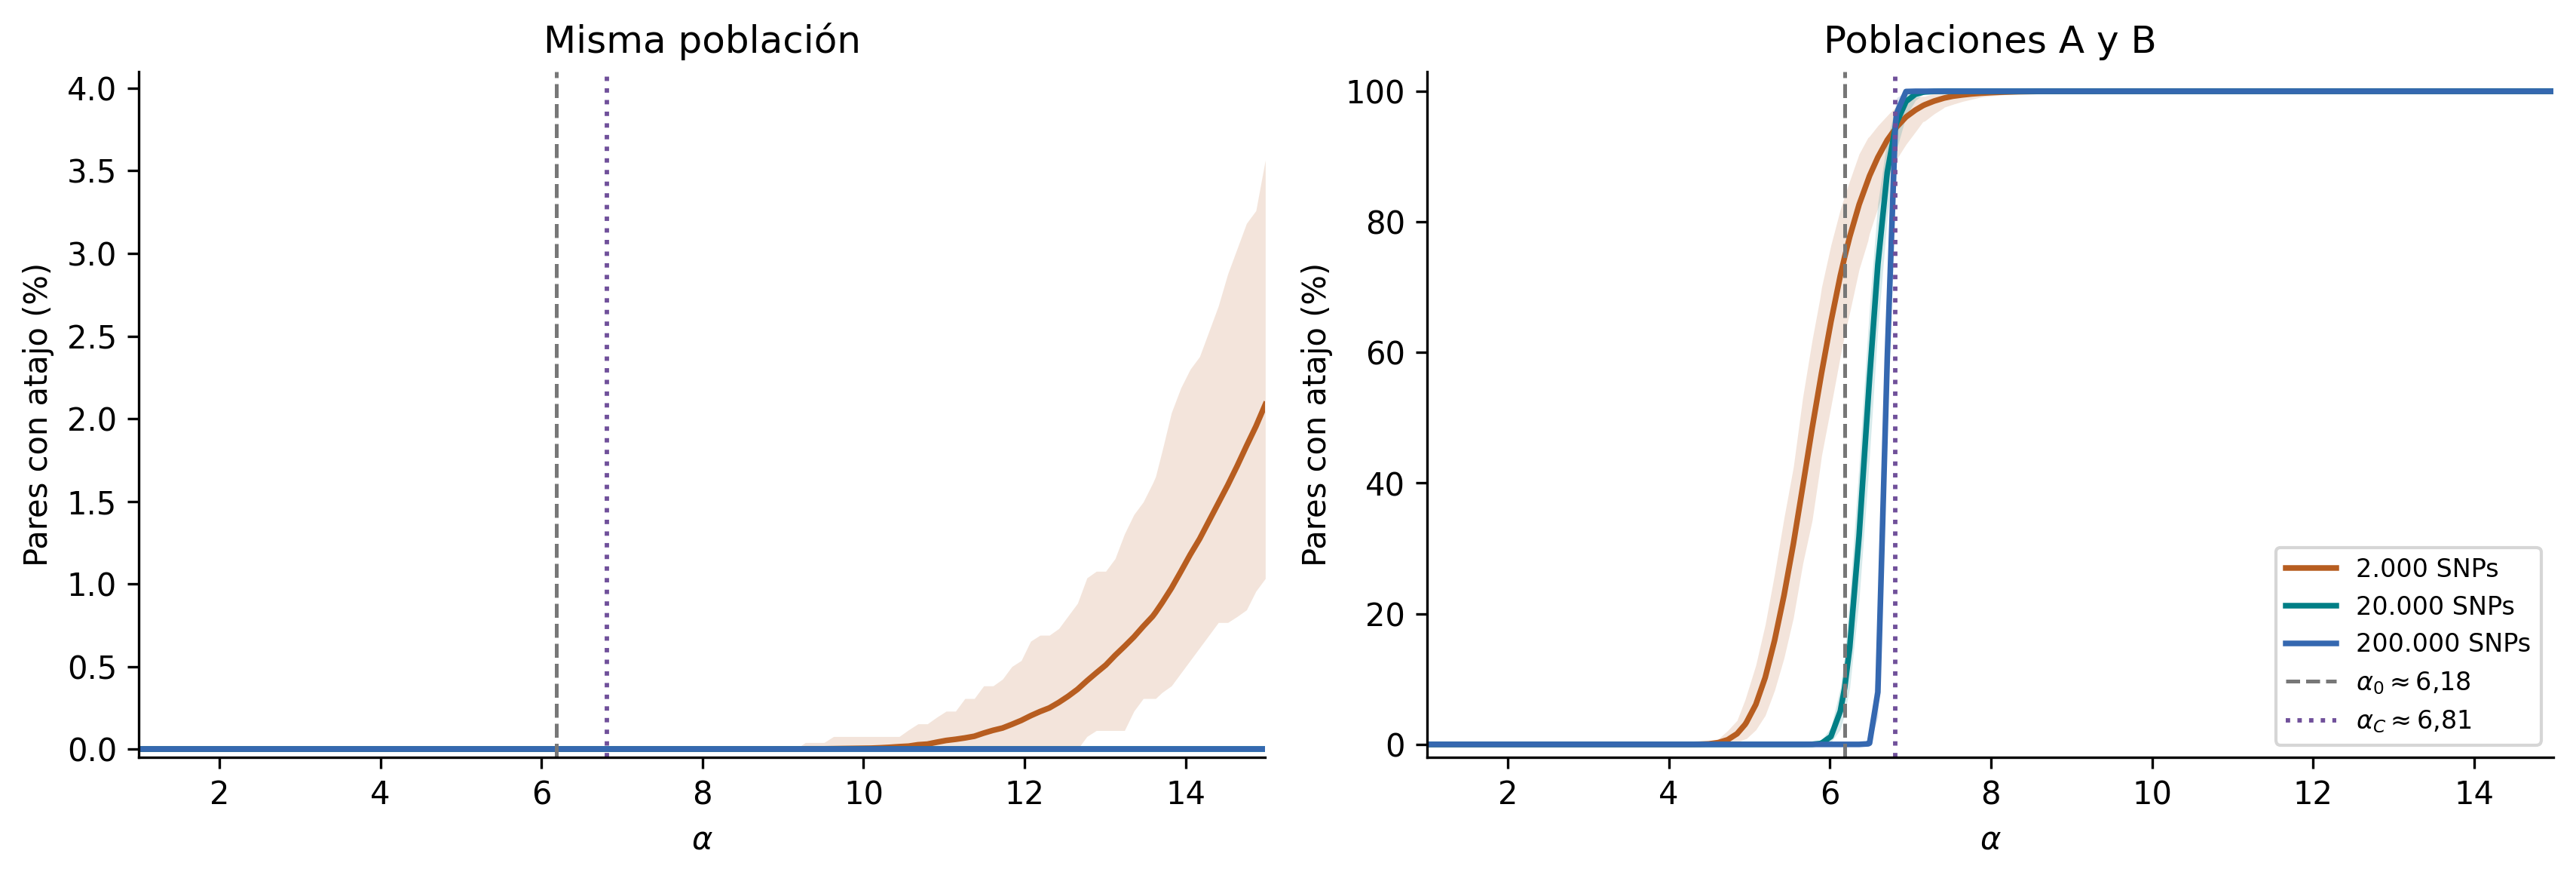

In [6]:
resumen = atajos.groupby(['SNPs', 'alpha']).agg(
    intra_media=('intra', 'mean'),
    intra_p025=('intra', lambda x: x.quantile(.025)),
    intra_p975=('intra', lambda x: x.quantile(.975)),
    AB_media=('AB', 'mean'),
    AB_p025=('AB', lambda x: x.quantile(.025)),
    AB_p975=('AB', lambda x: x.quantile(.975)),
).reset_index()
guardar_tabla(resumen, 'atajos_resumen')

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4))
colores = ['#b75d20', '#007f86', '#3568b0']

for p, color in zip(P_VALORES, colores):
    t = resumen.loc[resumen['SNPs'] == p]
    for ax, prefijo in zip(axs, ['intra', 'AB']):
        ax.plot(t['alpha'], t[f'{prefijo}_media'], color=color, lw=1.8,
                label=f'{p:,} SNPs'.replace(',', '.'))
        ax.fill_between(t['alpha'], t[f'{prefijo}_p025'], t[f'{prefijo}_p975'],
                        color=color, alpha=.16, linewidth=0)

for ax in axs:
    ax.axvline(alpha_0, color='#777777', ls='--', lw=1.2,
               label=rf'$\alpha_0 \approx {alpha_0:.2f}$'.replace('.', '{,}'))
    ax.axvline(alpha_C, color='#70509a', ls=':', lw=1.4,
               label=rf'$\alpha_C \approx {alpha_C:.2f}$'.replace('.', '{,}'))
    ax.set(xlabel=r'$\alpha$', ylabel='Pares con atajo (%)',
           xlim=(grilla.min(), grilla.max()))

maximo_intra = resumen['intra_p975'].max()
axs[0].set(title='Misma población', ylim=(-.05, max(.2, 1.15 * maximo_intra)))
axs[1].set(title='Poblaciones A y B', ylim=(-2, 103))
axs[1].legend(fontsize=8, loc='lower right')

fig.tight_layout()
guardar_figura(fig, 'atajos_replicas')
plt.show()

El siguiente resumen permite comprobar los valores comentados en la Sección 5.1: el primer exponente de la grilla con algún atajo A–B, el primero en que los 900 pares A–B tienen atajo y el máximo de atajos intrapoblacionales. Son valores leídos de la grilla, no umbrales exactos.

In [7]:
filas = []
for (p, replica), t in atajos.groupby(['SNPs', 'replica']):
    t = t.sort_values('alpha')
    filas.append({
        'SNPs': p,
        'primer_AB': t.loc[t['AB'] > 0, 'alpha'].min(),
        'todos_AB': t.loc[t['AB'] == 100, 'alpha'].min(),
        'AB_en_alpha0': t.loc[np.isclose(t['alpha'], alpha_0), 'AB'].iloc[0],
        'max_intra': t['intra'].max(),
    })

transiciones = pd.DataFrame(filas)
comprobacion = transiciones.groupby('SNPs').agg(
    primer_AB=('primer_AB', 'mean'),
    todos_AB=('todos_AB', 'mean'),
    AB_en_alpha0=('AB_en_alpha0', 'mean'),
    max_intra=('max_intra', 'mean'),
    de_max_intra=('max_intra', 'std'),
)
display(comprobacion.round(3))

,primer_AB,todos_AB,AB_en_alpha0,max_intra,de_max_intra
SNPs,,,,,
2000,4.584,8.357,74.632,2.086,0.705
20000,5.902,7.252,8.661,0.000,0.000
200000,6.510,6.979,0.000,0.000,0.000
